# Homework 6 
### Maxwell Bederman

In [1]:
import math

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import KFold, cross_val_score
from sklearn.svm import SVC
from tqdm.auto import tqdm
from xgboost import XGBClassifier

/Users/maxwellbederman/Desktop/School/USC/Fall 2026/DSCI 552/dsci-552-homework-6/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1)

### a)

In [2]:
train_df = pd.read_csv("../data/aps_failure_training_set.csv", header=14)
train_df["class"] = train_df["class"].replace({"pos": 1, "neg": 0})
train_df = train_df.replace("na", None)
print(train_df.shape)
train_df.head(10)

(60000, 171)


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,0,76698,NaN,2130706438,280,0,0,0,0,0,...,1240520,493384,721044,469792,339156,157956,73224,0,0,0
1,0,33058,NaN,0,NaN,0,0,0,0,0,...,421400,178064,293306,245416,133654,81140,97576,1500,0,0
2,0,41040,NaN,228,100,0,0,0,0,0,...,277378,159812,423992,409564,320746,158022,95128,514,0,0
3,0,12,0,70,66,0,10,0,0,0,...,240,46,58,44,10,0,0,0,4,32
4,0,60874,NaN,1368,458,0,0,0,0,0,...,622012,229790,405298,347188,286954,311560,433954,1218,0,0
5,0,38312,NaN,2130706432,218,0,0,0,0,0,...,388574,288278,900430,300412,1534,338,856,0,0,0
6,0,14,0,6,NaN,0,0,0,0,0,...,168,48,60,28,0,0,0,0,0,0
7,0,102960,NaN,2130706432,116,0,0,0,0,0,...,715518,384948,915978,1052166,1108672,341532,129504,7832,0,0
8,0,78696,NaN,0,NaN,0,0,0,0,0,...,699290,362510,1190028,1012704,160090,63216,41202,4,0,0
9,1,153204,0,182,NaN,0,0,0,0,0,...,129862,26872,34044,22472,34362,0,0,0,0,0


In [3]:
X_train = train_df[train_df.columns[1:]]
y_train = train_df["class"]

In [4]:
test_df = pd.read_csv("../data/aps_failure_test_set.csv", header=14)
test_df["class"] = test_df["class"].replace({"pos": 1, "neg": 0})
test_df = test_df.replace("na", None)
print(test_df.shape)
test_df.head(10)

(16000, 171)


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,0,60,0,20,12,0,0,0,0,0,...,1098,138,412,654,78,88,0,0,0,0
1,0,82,0,68,40,0,0,0,0,0,...,1068,276,1620,116,86,462,0,0,0,0
2,0,66002,2,212,112,0,0,0,0,0,...,495076,380368,440134,269556,1315022,153680,516,0,0,0
3,0,59816,NaN,1010,936,0,0,0,0,0,...,540820,243270,483302,485332,431376,210074,281662,3232,0,0
4,0,1814,NaN,156,140,0,0,0,0,0,...,7646,4144,18466,49782,3176,482,76,0,0,0
5,0,174,NaN,26,24,0,0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0
6,0,40202,NaN,640,606,0,0,0,0,0,...,526218,239734,439556,374248,169096,53658,41054,320,0,0
7,0,120278,NaN,2130706432,256,0,0,0,0,0,...,1006722,459658,876356,689532,568540,500624,1006628,34820,0,0
8,0,14592,0,2130706438,162,0,0,0,0,0,...,105024,57398,49152,38256,243268,145144,0,0,0,0
9,0,28338,NaN,2130706432,238,0,0,0,0,0,...,357006,150056,264776,239282,140548,74750,32958,84,0,0


In [5]:
X_test = test_df[test_df.columns[1:]]
y_test = test_df["class"]

In [6]:
y_train = y_train.astype(int)
y_test = y_test.astype(int)

### b)

#### i)

In [7]:
imputer = SimpleImputer(strategy="median")

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train), columns=X_train.columns, index=X_train.index
)

X_train_imputed.head(10)

,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,ag_003,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,76698.0,0.0,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,33058.0,0.0,0.000000e+00,126.0,0.0,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,41040.0,0.0,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,12.0,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,318.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,60874.0,0.0,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0
5,38312.0,0.0,2.130706e+09,218.0,0.0,0.0,0.0,0.0,0.0,0.0,...,388574.0,288278.0,900430.0,300412.0,1534.0,338.0,856.0,0.0,0.0,0.0
6,14.0,0.0,6.000000e+00,126.0,0.0,0.0,0.0,0.0,0.0,0.0,...,168.0,48.0,60.0,28.0,0.0,0.0,0.0,0.0,0.0,0.0
7,102960.0,0.0,2.130706e+09,116.0,0.0,0.0,0.0,0.0,0.0,0.0,...,715518.0,384948.0,915978.0,1052166.0,1108672.0,341532.0,129504.0,7832.0,0.0,0.0
8,78696.0,0.0,0.000000e+00,126.0,0.0,0.0,0.0,0.0,0.0,0.0,...,699290.0,362510.0,1190028.0,1012704.0,160090.0,63216.0,41202.0,4.0,0.0,0.0
9,153204.0,0.0,1.820000e+02,126.0,0.0,0.0,0.0,0.0,0.0,11804.0,...,129862.0,26872.0,34044.0,22472.0,34362.0,0.0,0.0,0.0,0.0,0.0


In [8]:
X_test_imputed = pd.DataFrame(
    imputer.transform(X_test), columns=X_test.columns, index=X_test.index
)
X_test_imputed.head(10)

,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,ag_003,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,60.0,0.0,2.000000e+01,12.0,0.0,0.0,0.0,0.0,0.0,2682.0,...,1098.0,138.0,412.0,654.0,78.0,88.0,0.0,0.0,0.0,0.0
1,82.0,0.0,6.800000e+01,40.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1068.0,276.0,1620.0,116.0,86.0,462.0,0.0,0.0,0.0,0.0
2,66002.0,2.0,2.120000e+02,112.0,0.0,0.0,0.0,0.0,0.0,199486.0,...,495076.0,380368.0,440134.0,269556.0,1315022.0,153680.0,516.0,0.0,0.0,0.0
3,59816.0,0.0,1.010000e+03,936.0,0.0,0.0,0.0,0.0,0.0,0.0,...,540820.0,243270.0,483302.0,485332.0,431376.0,210074.0,281662.0,3232.0,0.0,0.0
4,1814.0,0.0,1.560000e+02,140.0,0.0,0.0,0.0,0.0,0.0,0.0,...,7646.0,4144.0,18466.0,49782.0,3176.0,482.0,76.0,0.0,0.0,0.0
5,174.0,0.0,2.600000e+01,24.0,0.0,0.0,0.0,0.0,0.0,0.0,...,233796.0,112086.0,221518.0,189988.0,92432.0,41098.0,3812.0,0.0,0.0,0.0
6,40202.0,0.0,6.400000e+02,606.0,0.0,0.0,0.0,0.0,0.0,0.0,...,526218.0,239734.0,439556.0,374248.0,169096.0,53658.0,41054.0,320.0,0.0,0.0
7,120278.0,0.0,2.130706e+09,256.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1006722.0,459658.0,876356.0,689532.0,568540.0,500624.0,1006628.0,34820.0,0.0,0.0
8,14592.0,0.0,2.130706e+09,162.0,0.0,0.0,0.0,0.0,0.0,0.0,...,105024.0,57398.0,49152.0,38256.0,243268.0,145144.0,0.0,0.0,0.0,0.0
9,28338.0,0.0,2.130706e+09,238.0,0.0,0.0,0.0,0.0,0.0,0.0,...,357006.0,150056.0,264776.0,239282.0,140548.0,74750.0,32958.0,84.0,0.0,0.0


#### ii)

In [9]:
CV = X_train_imputed.std() / X_train_imputed.mean()
CV = CV.sort_values(ascending=False)
CV.head(20)

cf_000    244.887517
co_000    244.507385
ad_000    244.322816
cs_009    237.930554
dh_000    123.216097
dj_000    117.494225
ag_000     92.917755
as_000     87.332500
ay_009     84.733735
ak_000     80.424975
az_009     77.838544
ch_000     77.453857
au_000     68.882751
cr_000     58.078072
ay_001     52.824714
df_000     52.292814
dz_000     51.332228
ef_000     49.366659
cs_008     48.102206
aj_000     44.265996
dtype: float64

#### iii)

In [10]:
def plot_correlation_heatmap(df, figsize=(16, 12)):
    corr = df.corr(numeric_only=True)

    plt.figure(figsize=figsize)
    sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True)
    plt.title("Feature Correlation Heatmap")
    plt.show()

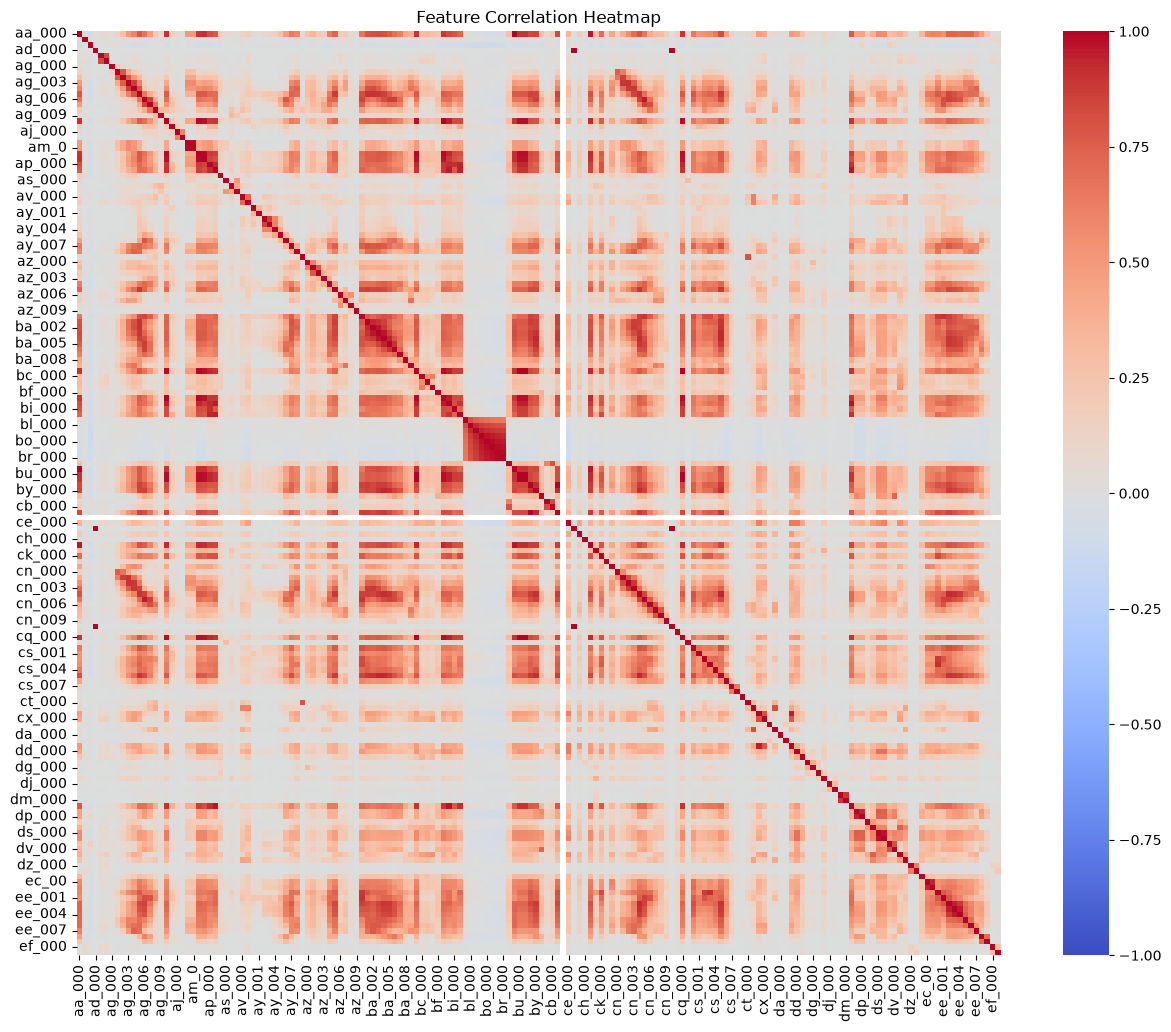

In [11]:
plot_correlation_heatmap(X_train_imputed)

#### iv)

In [12]:
def plot_feature_pairs(df, target_col):
    feature_cols = df.drop(columns=target_col).select_dtypes(include="number").columns
    classes = df[target_col].dropna().unique()
    n_features = len(feature_cols)

    colors = {cls: color for cls, color in zip(classes, ["tab:blue", "tab:orange"])}

    fig, axes = plt.subplots(
        n_features,
        n_features,
        figsize=(2.3 * n_features + 1.5, 2.3 * n_features),
        squeeze=False,
        layout="constrained",
    )

    for row, y_col in enumerate(feature_cols):
        for col, x_col in enumerate(feature_cols):
            ax = axes[row, col]

            if row == col:
                ax.text(
                    0.5,
                    0.5,
                    x_col,
                    ha="center",
                    va="center",
                    fontsize=8,
                    fontweight="bold",
                    wrap=True,
                    transform=ax.transAxes,
                )
                ax.set_xticks([])
                ax.set_yticks([])

            else:
                plot_data = df[[x_col, y_col, target_col]].dropna()

                for cls in classes:
                    subset = plot_data[plot_data[target_col] == cls]
                    ax.scatter(
                        subset[x_col],
                        subset[y_col],
                        color=colors[cls],
                        alpha=0.7,
                        s=8,
                    )

                ax.tick_params(labelsize=6)

            if row == n_features - 1:
                ax.set_xlabel(x_col, fontsize=7)

            if col == 0:
                ax.set_ylabel(y_col, fontsize=7)

    handles = [
        mpl.lines.Line2D(
            [0],
            [0],
            marker="o",
            linestyle="",
            color=colors[cls],
            label=str(cls),
            markersize=6,
        )
        for cls in classes
    ]

    fig.legend(
        handles=handles,
        title=target_col,
        loc="center left",
        bbox_to_anchor=(1.01, 0.5),
        fontsize=9,
    )

    fig.subplots_adjust(right=0.85)
    plt.show()


def plot_feature_boxplots(df, ncols=4):
    features = df.columns
    nrows = math.ceil(len(features) / ncols)

    fig, axes = plt.subplots(
        nrows, ncols, figsize=(4 * ncols, 4 * nrows), squeeze=False
    )
    axes = axes.flatten()

    for ax, feature in zip(axes, features):
        ax.boxplot(df[feature].dropna())
        ax.set_title(feature)
        ax.set_ylabel("Value")

    for ax in axes[len(features) :]:
        ax.set_visible(False)

    plt.tight_layout()
    plt.show()

In [13]:
p = math.floor(math.sqrt(170))
features = list(CV.index[:p])
features

['cf_000',
 'co_000',
 'ad_000',
 'cs_009',
 'dh_000',
 'dj_000',
 'ag_000',
 'as_000',
 'ay_009',
 'ak_000',
 'az_009',
 'ch_000',
 'au_000']

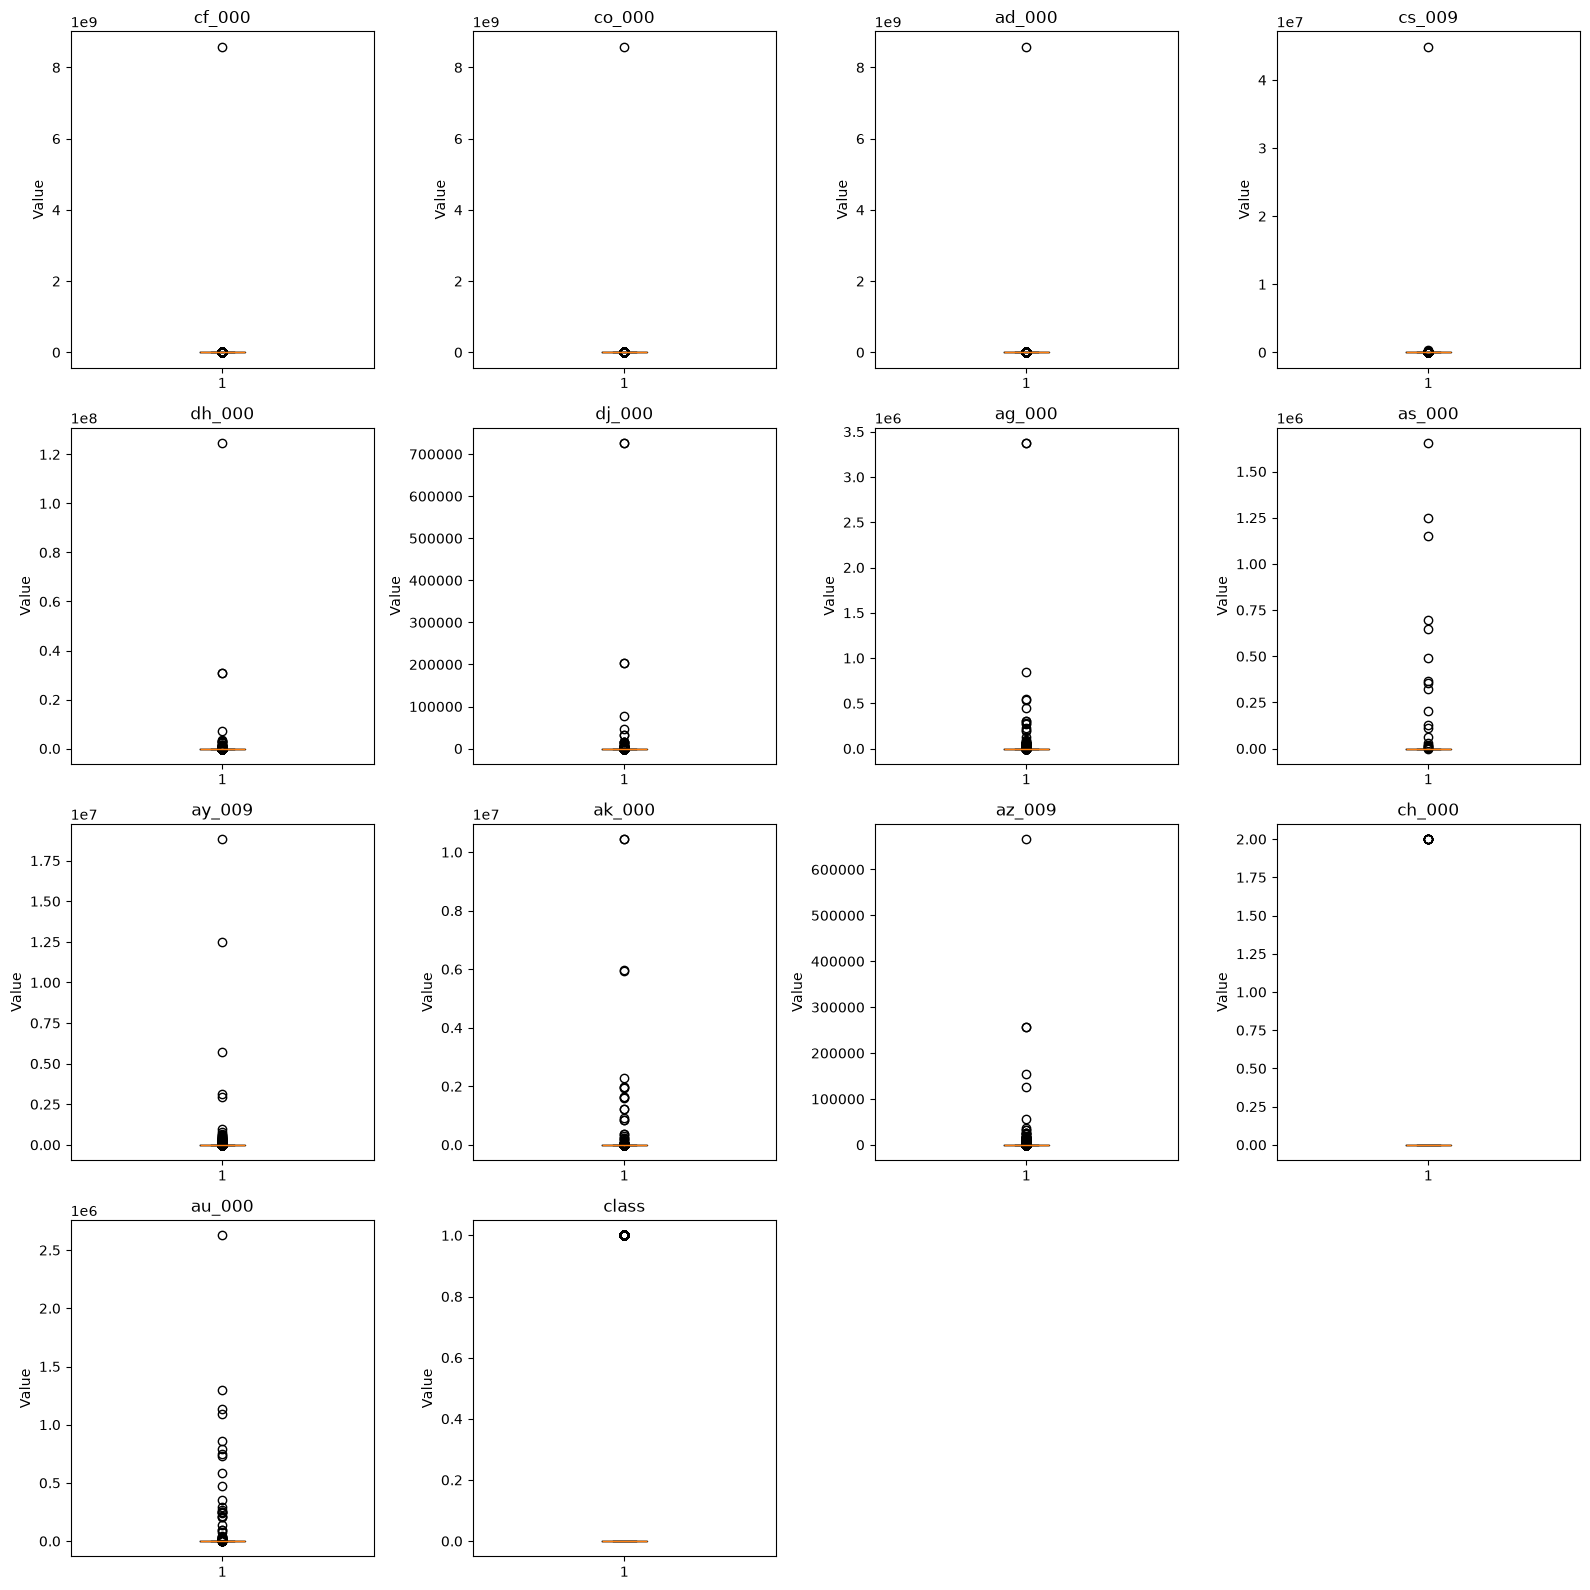

/var/folders/wz/dvph41sd38x6rxm2cyvp85v40000gn/T/ipykernel_65137/619468417.py:77: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(right=0.85)


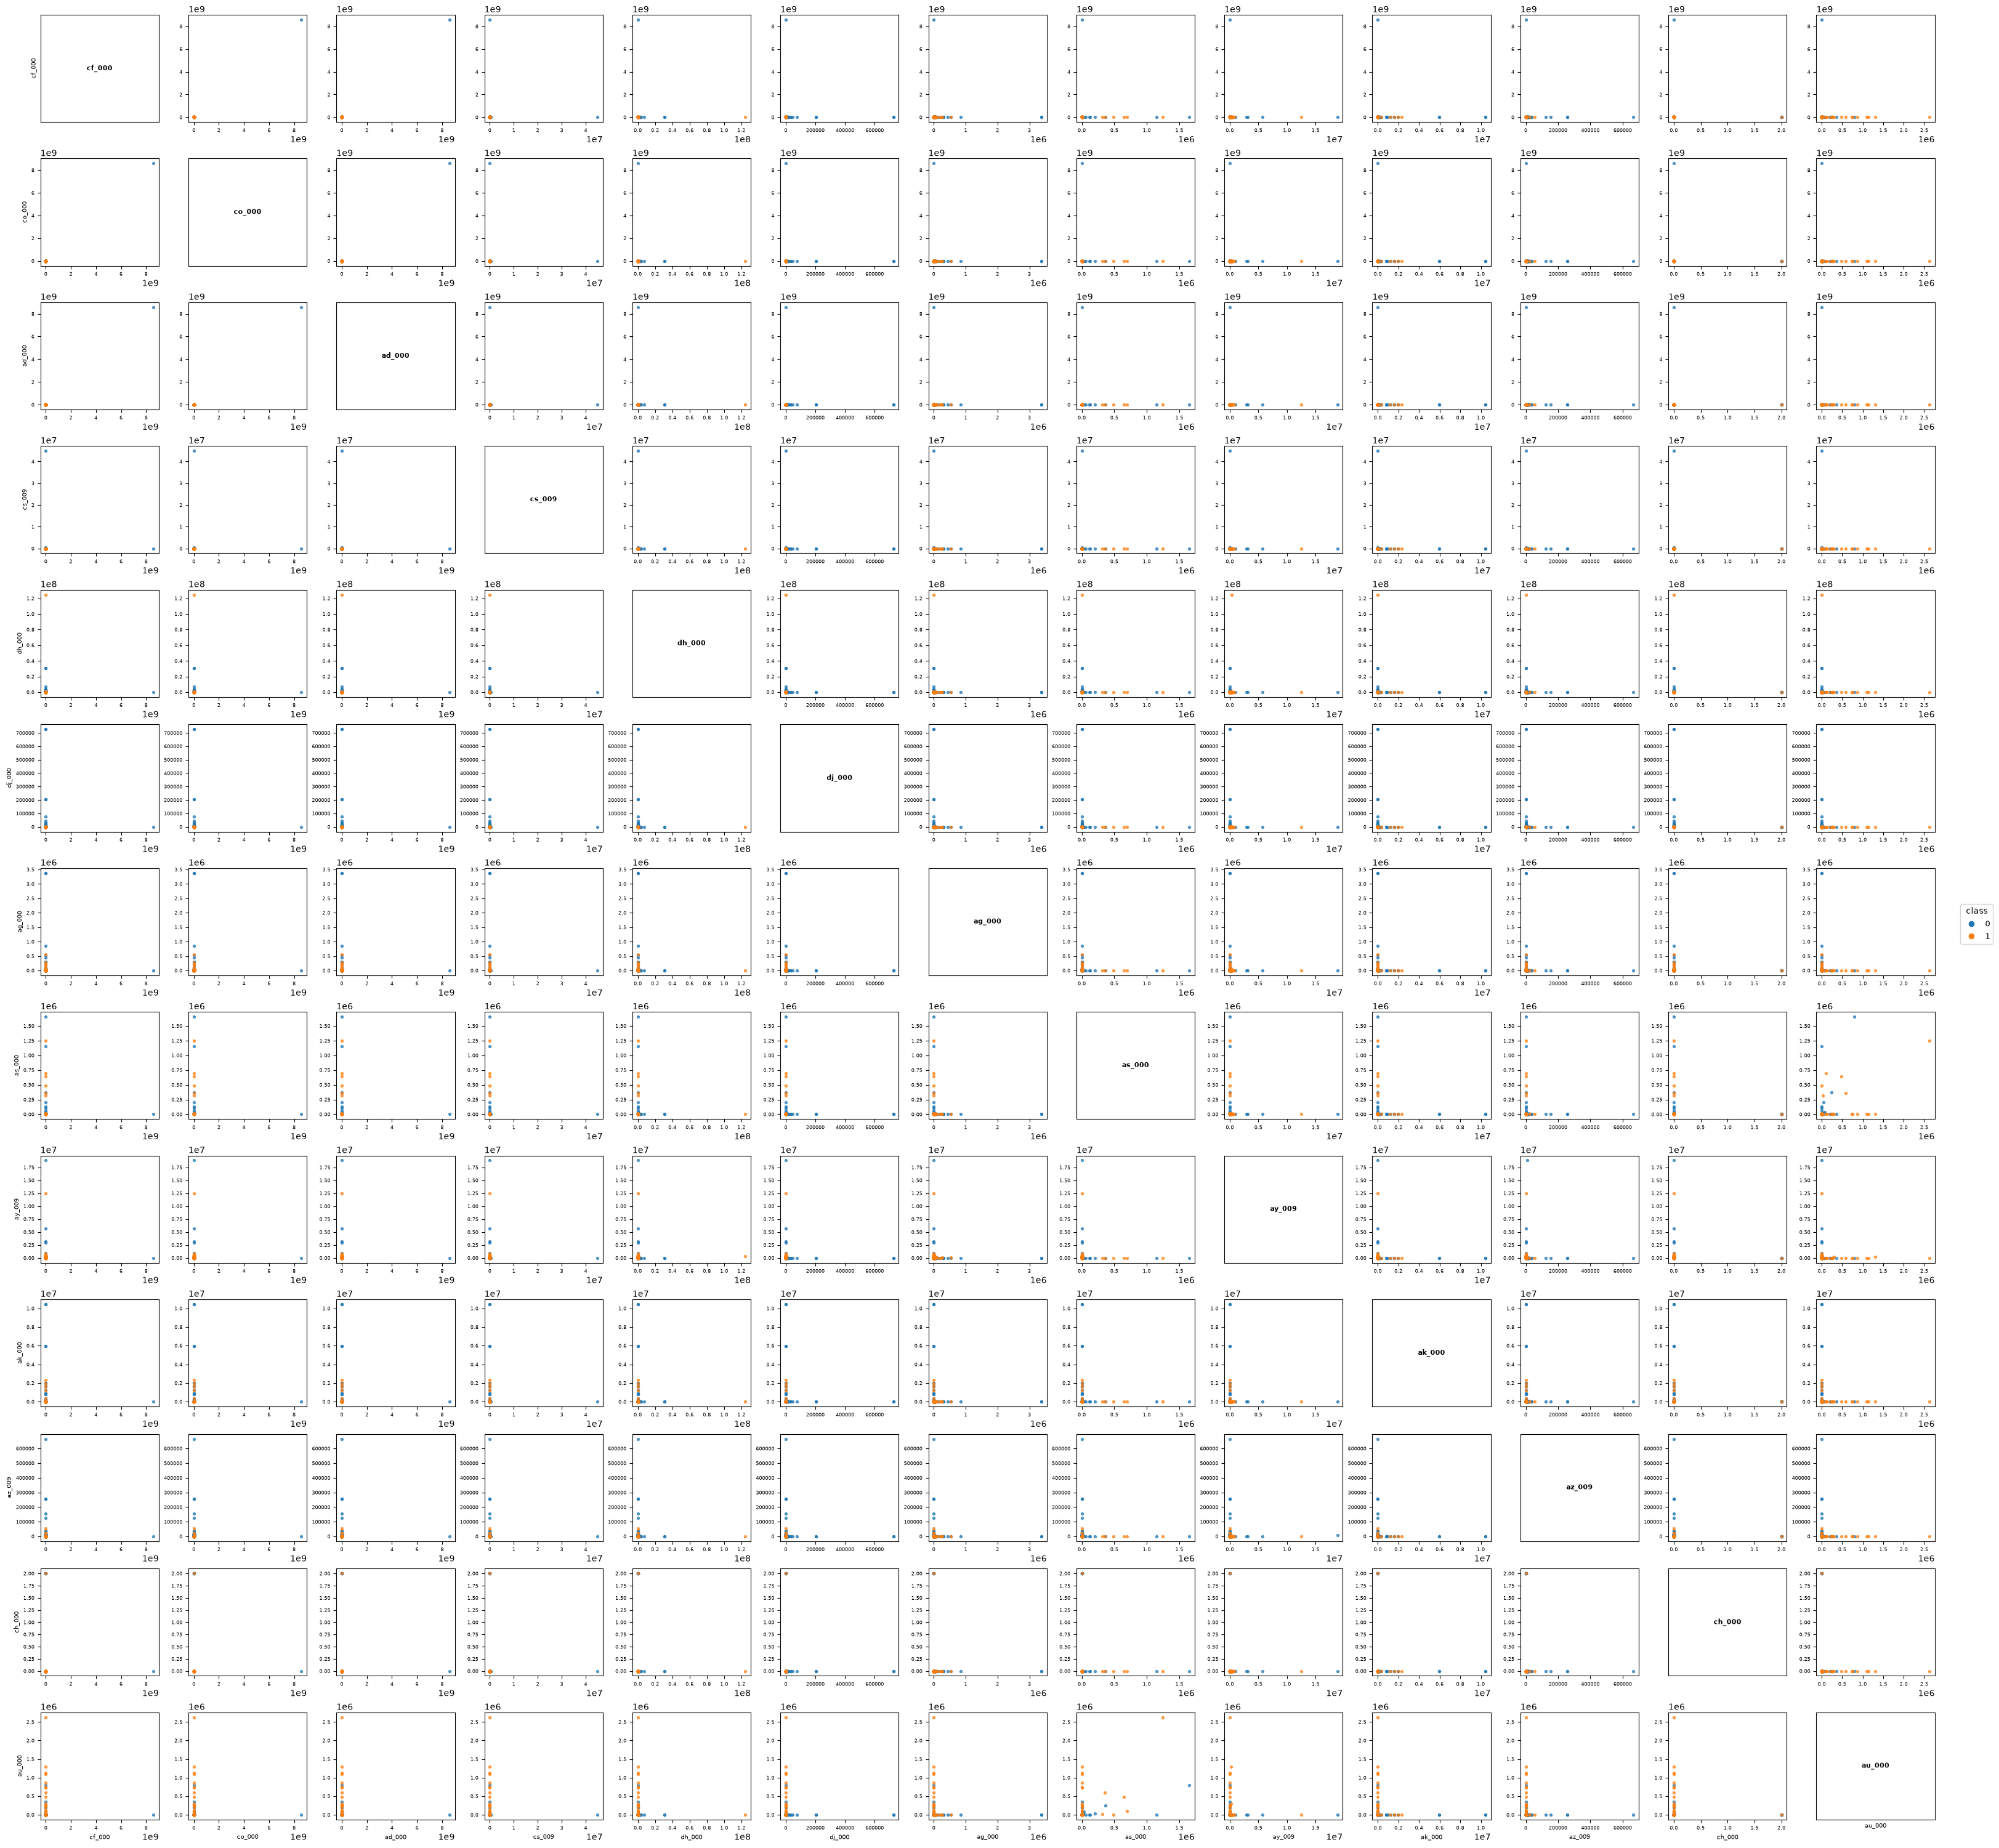

In [14]:
X_train_imputed_df_plotting = X_train_imputed.copy()
X_train_imputed_df_plotting["class"] = y_train
X_train_imputed_df_plotting = X_train_imputed_df_plotting[features + ["class"]]
plot_feature_boxplots(X_train_imputed_df_plotting)
plot_feature_pairs(X_train_imputed_df_plotting, "class")

It seems like there is a pretty strong outlier in the dataset that caused us to pick these features to visualize because of the high CV. That being said you can see that in some features higher values coresponding with negative labels.

#### v)

In [15]:
print(f"# of negative data points in train set: {int((y_train == 0).sum())}")

# of negative data points in train set: 59000


In [16]:
print(f"# of positive data points in train set: {int((y_train == 1).sum())}")

# of positive data points in train set: 1000


There is pretty extreme class imbalance only 1/60 of the train data has a positive label.

### c)

In [17]:
def evaluate_classifier(model, X, y, title="Model Evaluation", oob=False):
    y_pred = model.predict(X)
    y_prob = model.predict_proba(X)[:, 1]

    auc = roc_auc_score(y, y_prob)
    misclassification = 1 - accuracy_score(y, y_pred)
    cm = confusion_matrix(y, y_pred, labels=model.classes_)

    print(f"{title}")
    print(f"ROC AUC: {auc:.4f}")
    print(f"Misclassification Rate: {misclassification:.4f}")

    if oob:
        if hasattr(model, "oob_score_"):
            print(f"OOB Error: {1 - model.oob_score_:.4f}")
        else:
            print("OOB Error unavailable. Train with oob_score=True.")

    fpr, tpr, thresholds = roc_curve(y, y_prob)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].plot(fpr, tpr, label=f"AUC = {auc:.4f}")
    axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
    axes[0].set_xlabel("False Positive Rate")
    axes[0].set_ylabel("True Positive Rate")
    axes[0].set_title(f"{title} - ROC Curve")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_).plot(
        ax=axes[1], cmap="Blues", colorbar=False
    )

    axes[1].set_title(f"{title} - Confusion Matrix")

    plt.tight_layout()
    plt.show()

    return {
        "auc": auc,
        "misclassification": misclassification,
        "confusion_matrix": cm,
        "oob_error": 1 - model.oob_score_
        if oob and hasattr(model, "oob_score_")
        else None,
    }

In [18]:
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_leaf=2,
    random_state=552,
    n_jobs=-1,
    bootstrap=True,
    oob_score=True,
)

rf.fit(X_train_imputed, y_train)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_true, y_pred)` to use acustom metric. Only available if `bootstrap=True`.For an illustration of out-of-bag (OOB) error estimation, see the example:ref:`sphx_glr_auto_examples_ensemble_plot_ensemble_oob.py`.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",552
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion

In [19]:
y_pred_train = rf.predict(X_train_imputed)
y_prob_train = rf.predict_proba(X_train_imputed)[:, 1]
y_pred_test = rf.predict(X_test_imputed)
y_prob_test = rf.predict_proba(X_test_imputed)[:, 1]

Random Forest Train Set
ROC AUC: 1.0000
Misclassification Rate: 0.0011
OOB Error: 0.0064


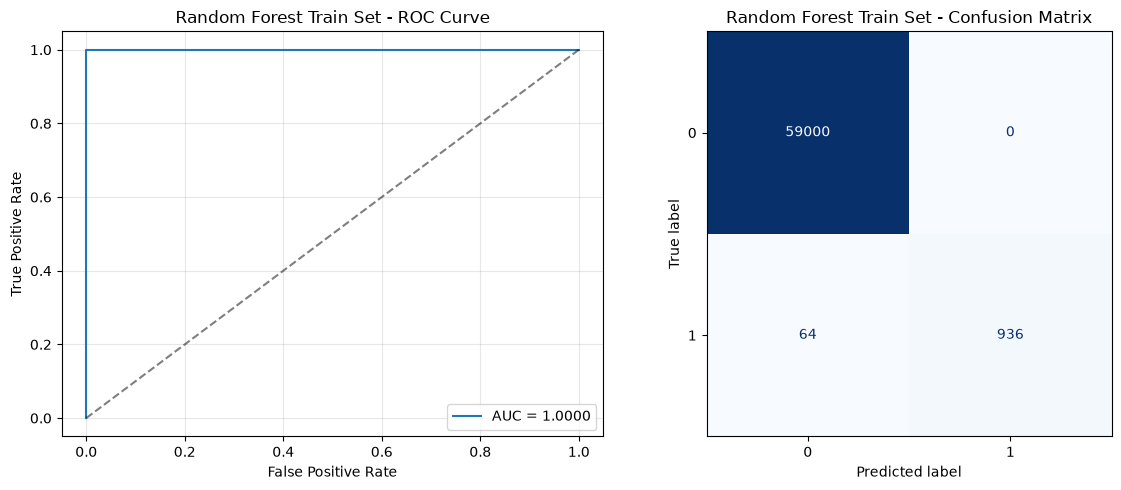

In [20]:
rf_train_results = evaluate_classifier(
    rf, X_train_imputed, y_train, title="Random Forest Train Set", oob=True
)

Random Forest Test Set
ROC AUC: 0.9942
Misclassification Rate: 0.0080


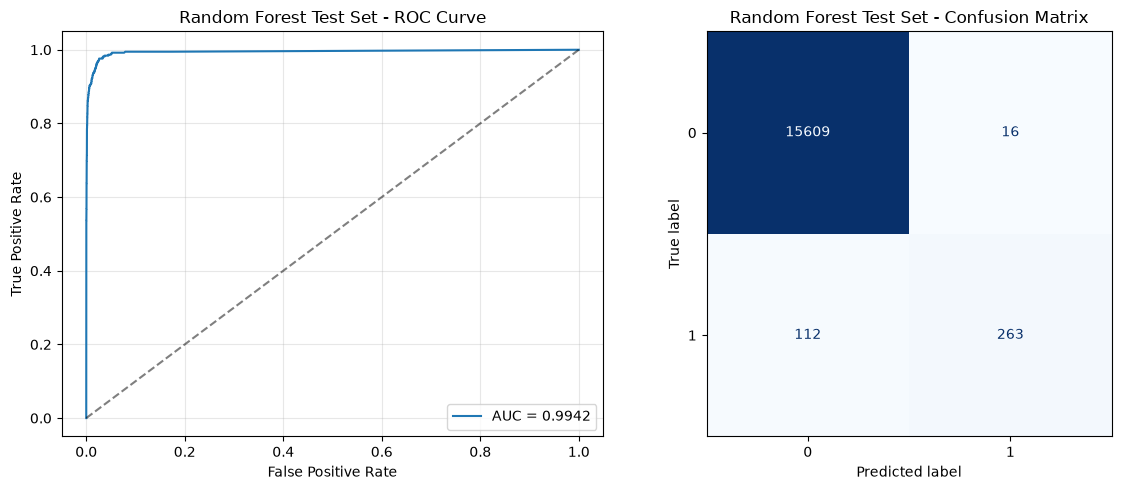

In [21]:
rf_test_results = evaluate_classifier(
    rf, X_test_imputed, y_test, title="Random Forest Test Set"
)

The OOB error is better than the test error so the model is performing worse on unseen data than expected.

### d)

In [22]:
balanced_rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_leaf=2,
    random_state=552,
    n_jobs=-1,
    class_weight="balanced",
    oob_score=True,
)

balanced_rf.fit(X_train_imputed, y_train)

/Users/maxwellbederman/Desktop/School/USC/Fall 2026/DSCI 552/dsci-552-homework-6/.venv/lib/python3.12/site-packages/sklearn/ensemble/_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_true, y_pred)` to use acustom metric. Only available if `bootstrap=True`.For an illustration of out-of-bag (OOB) error estimation, see the example:ref:`sphx_glr_auto_examples_ensemble_plot_ensemble_oob.py`.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",552
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fraction

In [23]:
y_pred_train = balanced_rf.predict(X_train_imputed)
y_prob_train = balanced_rf.predict_proba(X_train_imputed)[:, 1]
y_pred_test = balanced_rf.predict(X_test_imputed)
y_prob_test = balanced_rf.predict_proba(X_test_imputed)[:, 1]

Balanced Random Forest Train Set
ROC AUC: 1.0000
Misclassification Rate: 0.0017
OOB Error: 0.0214


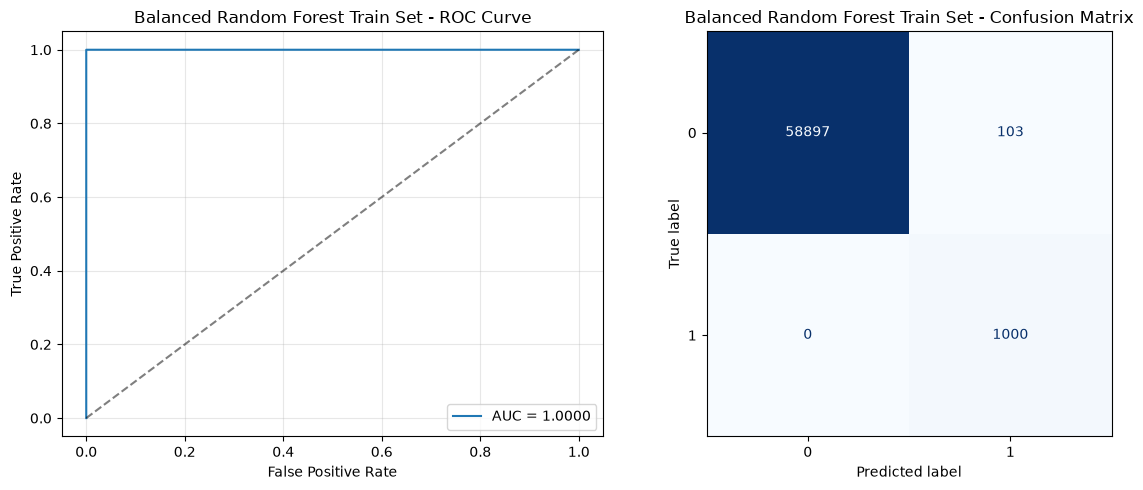

In [24]:
balanced_rf_train_results = evaluate_classifier(
    balanced_rf,
    X_train_imputed,
    y_train,
    title="Balanced Random Forest Train Set",
    oob=True,
)

Balanced Random Forest Test Set
ROC AUC: 0.9944
Misclassification Rate: 0.0098


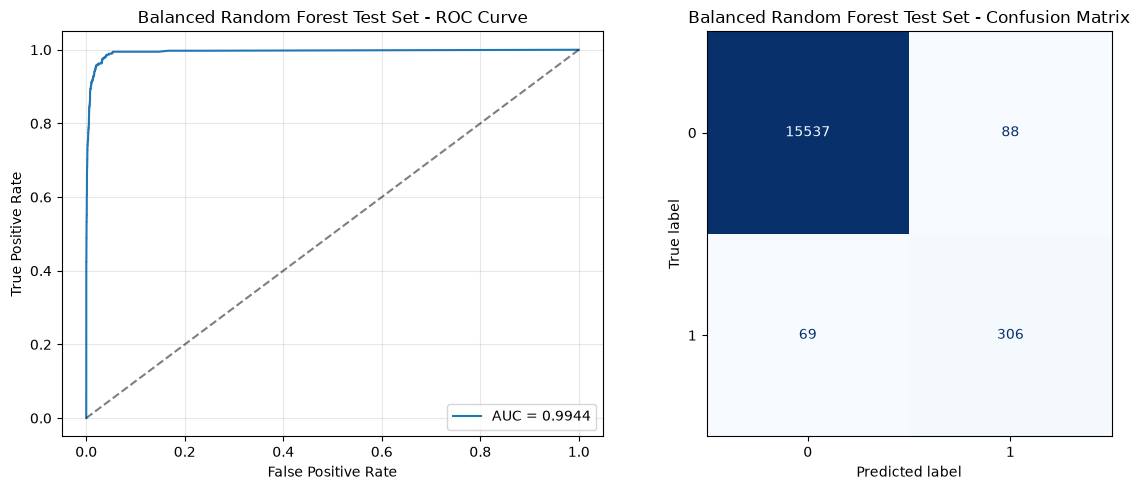

In [25]:
balanced_rf_test_results = evaluate_classifier(
    balanced_rf, X_test_imputed, y_test, title="Balanced Random Forest Test Set"
)

In the balanced case, the OOB error is much higher than the test error signaling that the model is generalizing pretty well to unseen data. This is because we have helped the model see the positive class more frequently at the expense of train accuracy on the negative class.

### e)

In [26]:
alphas = [10**k for k in range(-5, 6)]
cv = KFold(n_splits=5, shuffle=True, random_state=552)

results = []

for alpha in tqdm(alphas):
    xgb = XGBClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.05,
        reg_alpha=alpha,
        reg_lambda=0.0,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=552,
        n_jobs=-1,
    )

    roc_auc_scores = cross_val_score(
        xgb,
        X_train_imputed,
        y_train,
        cv=cv,
        scoring="roc_auc",
    )

    results.append(
        {
            "alpha": alpha,
            "roc_auc": roc_auc_scores.mean(),
        }
    )

results_df = pd.DataFrame(results).sort_values("roc_auc", ascending=False)
results_df

100%|██████████| 11/11 [00:44<00:00,  4.07s/it]


,alpha,roc_auc
5,1.00000,0.991423
6,10.00000,0.990655
0,0.00001,0.990271
3,0.01000,0.990071
1,0.00010,0.989970
4,0.10000,0.989961
2,0.00100,0.989954
7,100.00000,0.983323
8,1000.00000,0.500000
9,10000.00000,0.500000


In [27]:
alpha_star = results_df["alpha"].iloc[0]
alpha_star

np.float64(1.0)

In [28]:
xgb = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    reg_alpha=alpha_star,
    reg_lambda=0.0,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=552,
    n_jobs=-1,
)

xgb.fit(X_train_imputed, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


XGBoost Train Set
ROC AUC: 0.9996
Misclassification Rate: 0.0013


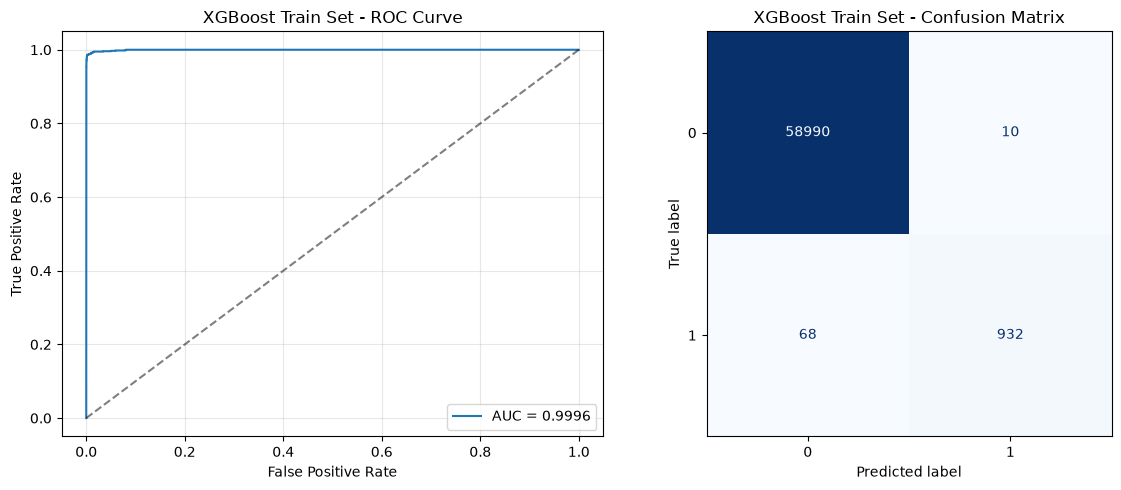

In [29]:
xgb_train_results = evaluate_classifier(
    xgb,
    X_train_imputed,
    y_train,
    title="XGBoost Train Set",
)

XGBoost Test Set
ROC AUC: 0.9961
Misclassification Rate: 0.0065


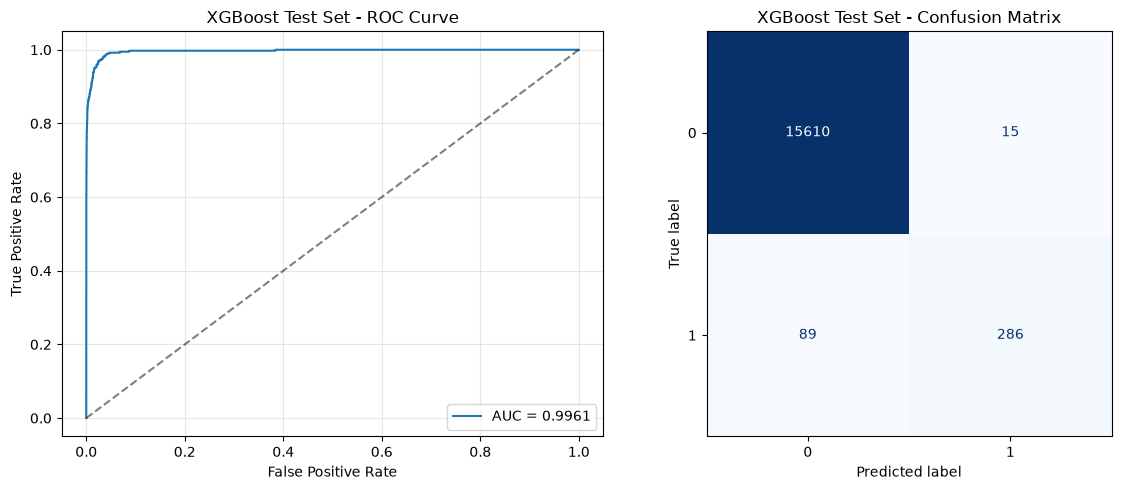

In [30]:
xgb_test_results = evaluate_classifier(
    xgb,
    X_test_imputed,
    y_test,
    title="XGBoost Test Set",
)

### f)

In [31]:
alphas = [10**k for k in range(-5, 6)]
cv = KFold(n_splits=5, shuffle=True, random_state=552)

results = []

for alpha in tqdm(alphas):
    pipeline = Pipeline(
        [
            ("smote", SMOTE(random_state=552)),
            (
                "xgb",
                XGBClassifier(
                    n_estimators=200,
                    max_depth=5,
                    learning_rate=0.05,
                    reg_alpha=alpha,
                    reg_lambda=0.0,
                    objective="binary:logistic",
                    eval_metric="logloss",
                    random_state=552,
                    n_jobs=-1,
                ),
            ),
        ]
    )

    roc_auc_scores = cross_val_score(
        pipeline,
        X_train_imputed,
        y_train,
        cv=cv,
        scoring="roc_auc",
    )

    results.append(
        {
            "alpha": alpha,
            "roc_auc": roc_auc_scores.mean(),
        }
    )

results_df = pd.DataFrame(results).sort_values("roc_auc", ascending=False)
results_df

100%|██████████| 11/11 [01:26<00:00,  7.90s/it]


,alpha,roc_auc
5,1.00000,0.988152
4,0.10000,0.988136
2,0.00100,0.988084
3,0.01000,0.988033
1,0.00010,0.988018
0,0.00001,0.988007
6,10.00000,0.987591
7,100.00000,0.985727
8,1000.00000,0.981860
9,10000.00000,0.968659


In [32]:
alpha_star = results_df["alpha"].iloc[0]
alpha_star

np.float64(1.0)

In [33]:
smote_xgb = Pipeline(
    [
        ("smote", SMOTE(random_state=552)),
        (
            "xgb",
            XGBClassifier(
                n_estimators=200,
                max_depth=5,
                learning_rate=0.05,
                reg_alpha=alpha_star,
                reg_lambda=0.0,
                objective="binary:logistic",
                eval_metric="logloss",
                random_state=552,
                n_jobs=-1,
            ),
        ),
    ]
)

smote_xgb.fit(X_train_imputed, y_train)

,steps,"[('smote', ...), ('xgb', ...)]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](170,)","['aa_000','ab_000','ac_000',...,'ee_009','ef_000','eg_000']"
n_features_in_,int,170
,random_state,552
,sampling_strategy,'auto'
,k_neighbors,5


SMOTE XGBoost Train Set
ROC AUC: 0.9985
Misclassification Rate: 0.0068


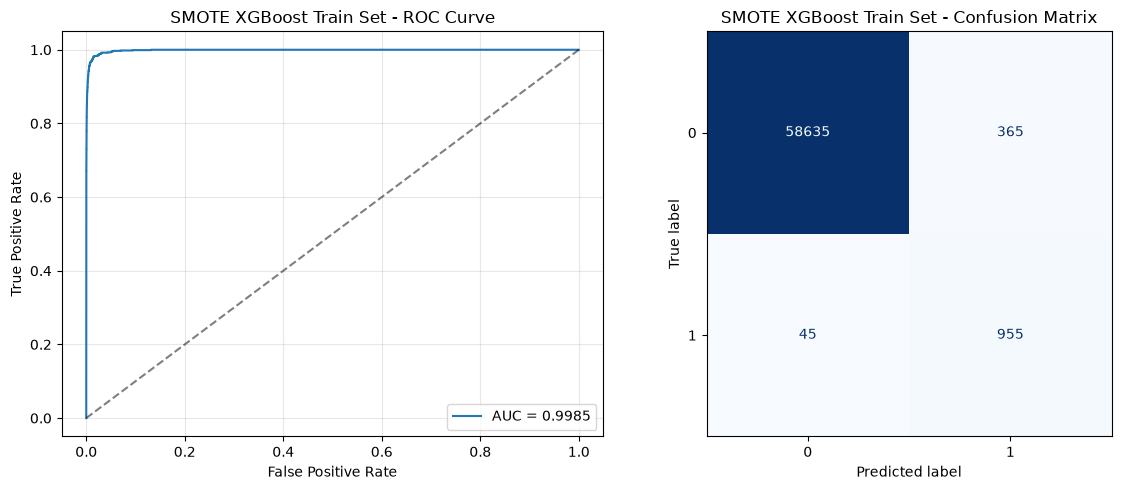

In [34]:
smote_xgb_train_results = evaluate_classifier(
    smote_xgb,
    X_train_imputed,
    y_train,
    title="SMOTE XGBoost Train Set",
)

SMOTE XGBoost Test Set
ROC AUC: 0.9947
Misclassification Rate: 0.0111


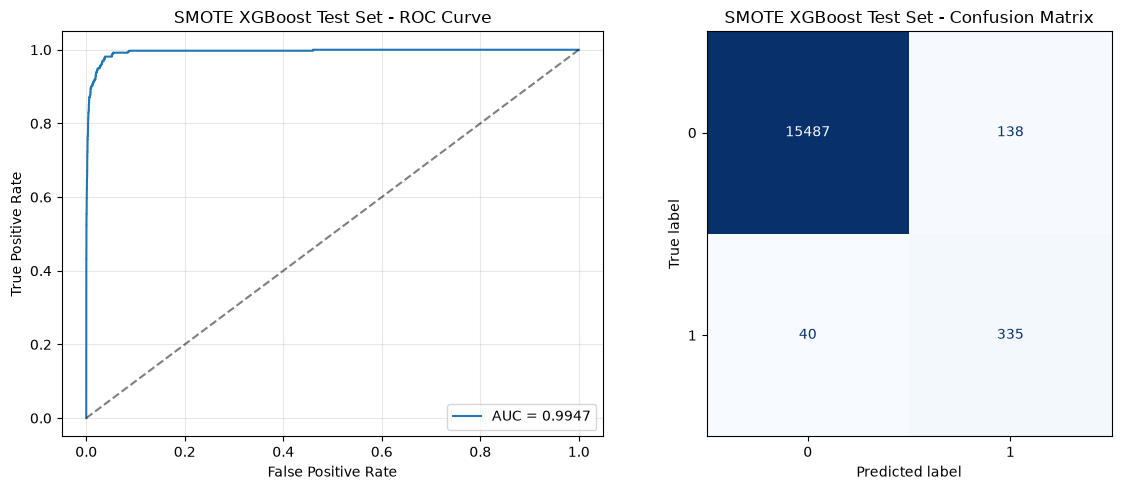

In [35]:
smote_xgb_test_results = evaluate_classifier(
    smote_xgb,
    X_test_imputed,
    y_test,
    title="SMOTE XGBoost Test Set",
)

The SMOTE case sacrificed train and test accuracy on the negative class in order to be able to generalize better to the positive class. Even though the overall accuracy is worse on the SMOTE case, its performance on the test set has greatly incrased for the positive class so in this use case where we are identifying component failures in trucks, we would rather predict some components that are working as failures if it means we can prevent more failures going unaccounted for. 

## 2) ISLR 6.6.3

### a)
iv, because as we allow the parameter vector to grow it is just given more freedom to fit to the training data so its bias will just decrease until it hits the minimum which is the unconstrained regression coefficients.

### b)
ii, as we increase s the bias will decrease however once s gets big enough variance will start to increase decreasing performance on unseen data and counteracting the improvements we saw initially.

### c)
iii, as s increases we are increasing the variance and decreasing the bias of our model because we allow the parameters to grow. This will steadily increase the variance until we reach unregularized linear regression which is the minimum variance of unbiased models.

### d)
iv, s at 0 is essentially full bias and no variance model and as we increase s the variance will increase and the bias will decrease until we reach the unbiased regression model which is just unregularized linear regression.

### e)
v, irreducible error is inherently unchangeable and no model can affect it.

## 3) ISLR 6.6.5

### a)

minimize $(y_1 - \beta_1x_{1 1} - \beta_2x_{1 2})^2 + (y_2 - \beta_1x_{2 1} - \beta_2x_{2 2})^2 + \lambda(\beta_1^2 + \beta_2^2)$

### b)

$$ L = (y_1 - \beta_1x_{1 1} - \beta_2x_{1 2})^2 + (y_2 - \beta_1x_{2 1} - \beta_2x_{2 2})^2 + \lambda(\beta_1^2 + \beta_2^2) \\
\text{Use } x_{11} = x_{12} \text{ and } x_{21} = x_{22} \text { then differentiate:} \\
\frac{\partial L}{\partial \beta_1} = -2x_{11}(y_1 - x_{11}(\beta_1 + \beta_2)) -2x_{21}(y_1 - x_{21}(\beta_1 + \beta_2)) + 2\lambda \beta_1 = 0 \\
\frac{\partial L}{\partial \beta_2} = -2x_{11}(y_1 - x_{11}(\beta_1 + \beta_2)) -2x_{21}(y_1 - x_{21}(\beta_1 + \beta_2)) + 2\lambda \beta_2 = 0 \\
\frac{\partial L}{\partial \beta_1} - \frac{\partial L}{\partial \beta_2} = 2\lambda \beta_1 - 2\lambda \beta_2 = 0 \\
\text{So } \beta_1 = \beta_2 
$$

### c) 
minimize $(y_1 - \beta_1x_{1 1} - \beta_2x_{1 2})^2 + (y_2 - \beta_1x_{2 1} - \beta_2x_{2 2})^2 + \lambda(|\beta_1| + |\beta_2|)$

### d)
$$ L = (y_1 - \beta_1x_{1 1} - \beta_2x_{1 2})^2 + (y_2 - \beta_1x_{2 1} - \beta_2x_{2 2})^2 + \lambda(|\beta_1| + |\beta_2|) \\
\text{Use } x_{11} = x_{12} \text{ and } x_{21} = x_{22} \text { then differentiate:} \\
\frac{\partial L}{\partial \beta_1} = -2x_{11}(y_1 - x_{11}(\beta_1 + \beta_2)) -2x_{21}(y_1 - x_{21}(\beta_1 + \beta_2)) + \lambda sign(\beta_1) = 0 \\
\text{Use } x_{11} = -x_{21} \text{ and } y_1 = -y_2: \\
\frac{\partial L}{\partial \beta_1} = -4x_{11}(y_1 - x_{11}(\beta_1 + \beta_2)) + \lambda sign(\beta_1) = 0 \\
\frac{\partial L}{\partial \beta_2} = -4x_{11}(y_1 - x_{11}(\beta_1 + \beta_2)) + \lambda sign(\beta_2) = 0 \\
\frac{\partial L}{\partial \beta_1} - \frac{\partial L}{\partial \beta_2} = \lambda (sign(\beta_1) - sign(\beta_2)) = 0 \\
\text{So } sign(\beta_1) = sign(\beta_2) \\
\text{Now solve for } \beta_1 + \beta_2 \\
-4x_{11}(y_1 - x_{11}(\beta_1 + \beta_2)) + \lambda sign(\beta_1) = 0 \\
\beta_1 + \beta_2 = \frac{4x_{11}y_1 - \lambda sign(\beta_1)}{4x_{11}^2}
$$

These solutions are basically lines depending on the data and lambda but the positive and negative solutions come from lines with different intercepts. The betas must have the same sign.

## 4) ISLR 8.4.5

In [36]:
probs = [0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, 0.75]

In [37]:
red = 0
green = 0

for prob in probs:
    if prob >= 0.5:
        red += 1
    else:
        green += 1

print(
    f"Majority Polling: Green: {green}, Red: {red}, Decision: {'Green' if green > red else 'Red'}"
)

Majority Polling: Green: 4, Red: 6, Decision: Red


In [38]:
avg_prob = 0
for prob in probs:
    avg_prob += prob

avg_prob = avg_prob / len(probs)
print(f"Average Prob: {avg_prob}, Decision: {'Green' if avg_prob < 0.5 else 'Red'}")

Average Prob: 0.45, Decision: Green


## 5) ISLR 9.7.3

### a) and b)

In [39]:
df = pd.DataFrame(
    [
        (3, 4, "Red"),
        (2, 2, "Red"),
        (4, 4, "Red"),
        (1, 4, "Red"),
        (2, 1, "Blue"),
        (4, 3, "Blue"),
        (4, 1, "Blue"),
    ],
    columns=["x1", "x2", "label"],
)
df

,x1,x2,label
0,3,4,Red
1,2,2,Red
2,4,4,Red
3,1,4,Red
4,2,1,Blue
5,4,3,Blue
6,4,1,Blue


In [40]:
X = df[["x1", "x2"]]
y = df["label"]

svm = SVC(kernel="linear", C=1e6)
svm.fit(X, y)

w1, w2 = svm.coef_[0]
b = svm.intercept_[0]

slope = -w1 / w2
intercept = -b / w2

print(f"Slope: {slope:.4f}")
print(f"Intercept: {intercept:.4f}")

Slope: 1.0000
Intercept: -0.5000


In [41]:
def plot_classes(df, slope=None, intercept=None):
    fig, ax = plt.subplots()

    for label, group in df.groupby("label"):
        ax.scatter(group["x1"], group["x2"], label=label, color=label.lower())

    if slope is not None and intercept is not None:
        ax.axline(
            (0, intercept),
            slope=slope,
            color="black",
            linestyle="--",
            label=f"{intercept} + {slope if slope != 1 else ""}x1 - x2 = 0"
        )

    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
    plt.tight_layout()
    ax.grid(alpha=0.3)
    plt.show()

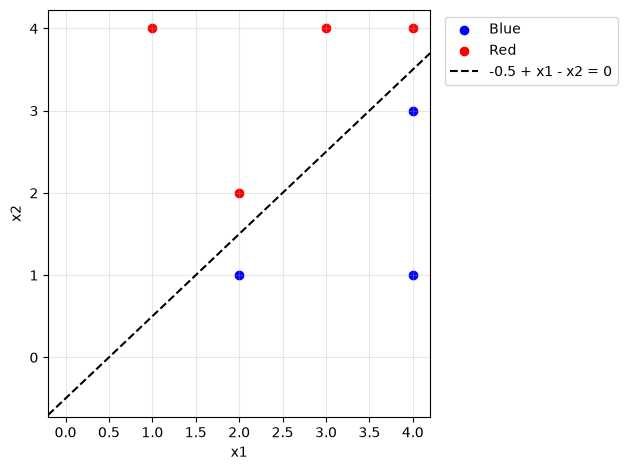

In [42]:
plot_classes(df, slope=1, intercept=-.5)

### c)

Classify to Red if -.5 + x1 - x2 > 0 and classify to Blue otherwise 

### d)

In [43]:
distances = abs(
    slope * df["x1"] - df["x2"] + intercept
) / np.sqrt(slope**2 + 1)

margin = distances.min()

print(f"Margin: {margin:.4f}")

Margin: 0.3536


### e)

In [44]:
support_vectors = df[np.isclose(distances, margin)]

print("Support Vectors:")
print(support_vectors)

Support Vectors:
   x1  x2 label
1   2   2   Red
2   4   4   Red
4   2   1  Blue
5   4   3  Blue


### f)
The seventh obstervation is not a support vector so moving it slighlty won't affect the margin at all and therefore won't change the boundary.

### g)

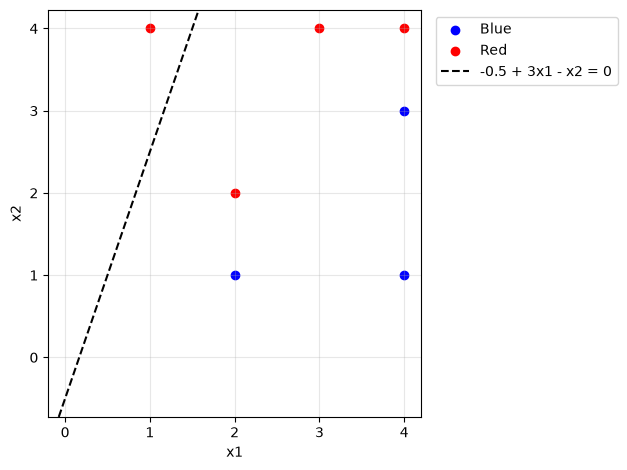

In [45]:
plot_classes(df, slope=3, intercept=-.5)

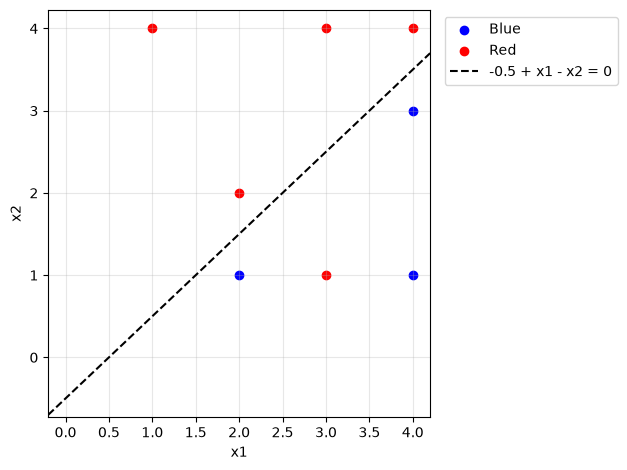

In [46]:
df2 = df.copy()
df2.loc[len(df2)] = [3, 1, "Red"]
plot_classes(df2, slope=1, intercept=-.5)